In [3]:
import sys

sys.path.append("..")  # zodat de map src gevonden wordt

from src.preprocessing import NUMERIC_COLS, StrokeData

data = StrokeData()
X, y = data.get_xy()       # features en target van de trainset
X_test = data.get_test()

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import (ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_val_score,
                                     train_test_split)

In [5]:
# Dezelfde split als in hoofdstuk 5: 80% train, 20% validatie
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| stroke-patiënten:", y_train.sum())
print("Validatie:", X_val.shape, "| stroke-patiënten:", y_val.sum())

Train: (26835, 15) | stroke-patiënten: 414
Validatie: (6709, 15) | stroke-patiënten: 103


### 6.1 K-Nearest Neighbors (KNN)

#### 6.1.1 Hoe werkt KNN?
KNN voorspelt een nieuwe patiënt op basis van de patiënten in de trainset die het meest op hem lijken:
1. KNN slaat alle patiënten uit de trainset op. Er wordt geen formule geleerd.
2. Voor een nieuwe patiënt berekent KNN de afstand tot iedere patiënt in de trainset. Hoe kleiner de afstand, hoe meer de patiënten op elkaar lijken.
3. KNN kiest de k patiënten met de kleinste afstand: de nearest neighbors.
4. De meerderheid van deze buren bepaalt de voorspelling. Het aandeel buren met een herseninfarct is tegelijk de kans op stroke (bijv. 2 van de 5 buren = 0,4).

**Afstandsmaten**
Voor twee patiënten $a$ en $b$ met $n$ features zijn er twee veelgebruikte afstandsmaten:

- **Euclidean distance**: de afstand "in een rechte lijn", zoals je met een liniaal meet:
$$d_{euclidean}(a, b) = \sqrt{\sum_{i=1}^{n} (a_i - b_i)^2}$$

- **Manhattan distance**: de afstand "langs de blokken", zoals je in een stad met rechte straten loopt. De verschillen per feature worden simpelweg opgeteld:
$$d_{manhattan}(a, b) = \sum_{i=1}^{n} |a_i - b_i|$$

In scikit-learn kies je de afstandsmaat met de hyperparameter `p`: `p=2` is euclidean (de standaard) en `p=1` is manhattan.

**Rekenvoorbeeld**
We berekenen beide afstanden voor de eerste twee patiënten uit de trainset, met alleen `age` en `avg_glucose_level`.

In [6]:
# Twee patiënten uit de trainset, alleen leeftijd en glucose
features = ["age", "avg_glucose_level"]
patient_a = X_train.iloc[0][features]
patient_b = X_train.iloc[1][features]
print("Patiënt A:", patient_a.to_dict())
print("Patiënt B:", patient_b.to_dict())

# Verschil per feature
verschil = patient_a - patient_b

# Euclidean: wortel van de som van de gekwadrateerde verschillen
euclidean = np.sqrt((verschil ** 2).sum())
# Manhattan: som van de absolute verschillen
manhattan = verschil.abs().sum()

print("Euclidean afstand:", round(euclidean, 2))
print("Manhattan afstand:", round(manhattan, 2))

Patiënt A: {'age': 19.0, 'avg_glucose_level': 96.92}
Patiënt B: {'age': 58.0, 'avg_glucose_level': 176.61}
Euclidean afstand: 88.72
Manhattan afstand: 118.69


**Berekening:** patiënt A is 19 jaar met een glucose van 96,92; patiënt B is 58 jaar met een glucose van 176,61. De verschillen zijn 39 jaar en 79,69 mg/dL.

$$d_{euclidean} = \sqrt{39^2 + 79{,}69^2} = \sqrt{1521 + 6350{,}50} = 88{,}72$$

$$d_{manhattan} = |39| + |79{,}69| = 118{,}69$$

De manhattan afstand is altijd groter of gelijk aan de euclidean afstand, omdat je "om de hoek" loopt in plaats van rechtdoor. Welke afstandsmaat het beste werkt voor onze data, bepalen we met hyperparameter tuning (6.1.5).

#### 6.1.2 Waarom is standaardisatie belangrijk voor KNN?
KNN beslist alleen op basis van **afstanden**. Als features op verschillende schalen gemeten worden, bepaalt de feature met de grootste getallen de afstand, ongeacht of die feature belangrijker is.

In het rekenvoorbeeld hierboven is het verschil in glucose (79,69) twee keer zo groot als het verschil in leeftijd (39 jaar). Dat komt alleen doordat glucose in grotere getallen wordt uitgedrukt. Toch is leeftijd de sterkste voorspeller van een herseninfarct (zie 4.4).

Met **standaardisatie** (zie 4.8) zetten we iedere feature om naar gemiddelde 0 en standaardafwijking 1:
$$z = \frac{x - \mu}{\sigma}$$
Zo wordt een verschil uitgedrukt in "aantal standaardafwijkingen" en tellen alle features even zwaar mee. Hieronder berekenen we de afstanden opnieuw, nu na standaardisatie.

In [7]:
# Standaardiseer leeftijd en glucose; fit alleen op de trainset
scaler = StandardScaler().fit(X_train[features])
geschaald = scaler.transform(X_train[features].iloc[:2])
patient_a_z, patient_b_z = geschaald[0], geschaald[1]
print("Patiënt A (z-scores):", patient_a_z.round(2))
print("Patiënt B (z-scores):", patient_b_z.round(2))

# Dezelfde afstanden, nu op de gestandaardiseerde waarden
verschil_z = patient_a_z - patient_b_z
print("Euclidean afstand:", round(np.sqrt((verschil_z ** 2).sum()), 2))
print("Manhattan afstand:", round(np.abs(verschil_z).sum(), 2))

# Hoeveel draagt iedere feature bij aan de (euclidean) afstand?
aandeel_voor = verschil ** 2 / (verschil ** 2).sum()
aandeel_na = verschil_z ** 2 / (verschil_z ** 2).sum()
print("Aandeel in de afstand vóór standaardisatie:",
      aandeel_voor.round(2).to_dict())
print("Aandeel in de afstand na standaardisatie:  ",
      dict(zip(features, aandeel_na.round(2))))

Patiënt A (z-scores): [-1.01 -0.16]
Patiënt B (z-scores): [0.72 1.74]
Euclidean afstand: 2.57
Manhattan afstand: 3.63
Aandeel in de afstand vóór standaardisatie: {'age': 0.19, 'avg_glucose_level': 0.81}
Aandeel in de afstand na standaardisatie:   {'age': 0.46, 'avg_glucose_level': 0.54}


**Observaties:**
- **Vóór standaardisatie** komt **81%** van de afstand door glucose en maar 19% door leeftijd. KNN zou patiënten dus vooral op glucose vergelijken, alleen omdat glucose grotere getallen heeft.
- **Na standaardisatie** tellen beide features ongeveer even zwaar mee (46% en 54%). Een verschil van 39 jaar (1,73 standaardafwijkingen) weegt nu bijna even zwaar als een verschil van 79,69 mg/dL glucose (1,90 standaardafwijkingen).
- Zonder standaardisatie zou KNN de verkeerde patiënten als "buren" kiezen. Daarom standaardiseren we bij KNN altijd, binnen een pipeline, zodat de scaler alleen op de trainingsdata wordt gefit.

#### 6.1.3 Imbalanced data
**Waarom is de dataset imbalanced?**
Slechts 1,54% van de patiënten heeft een herseninfarct gehad (414 van de 26.835 in de trainset). Een herseninfarct is in de bevolking relatief zeldzaam; de data weerspiegelt dus de werkelijkheid. Een dataset waarin de ene klasse veel kleiner is dan de andere heet imbalanced.

**Waarom is dat een probleem voor KNN?**
KNN voorspelt op basis van de meerderheid van de buren. Omdat bijna alle patiënten geen herseninfarct hebben, zijn ook bijna alle buren gezond. KNN voorspelt daardoor (bijna) nooit "stroke", zelfs niet bij patiënten met een hoog risico.

We passen daarom twee technieken toe:

**1. Random undersampling**
We laten willekeurig een deel van de patiënten zonder herseninfarct weg uit de trainingsdata, totdat er een evenwichtigere verhouding overblijft. Met `sampling_strategy=0.5` blijven er op iedere stroke-patiënt 2 patiënten zonder stroke over (in plaats van 64). Zo hebben de stroke-patiënten veel meer kans om bij de buren te horen.
- *Voordeel:* het model let meer op de stroke-patiënten, en KNN wordt veel sneller doordat er minder patiënten zijn om afstanden mee te berekenen.
- *Nadeel:* we gooien informatie weg over patiënten zonder herseninfarct.

**2. Drempel aanpassen**
KNN berekent per patiënt een kans op stroke: het aandeel buren met een herseninfarct. Standaard voorspelt KNN "stroke" als die kans ≥ 0,5 is. Door de drempel te verlagen, voorspelt het model vaker "stroke" (hogere recall, meer vals alarm); door hem te verhogen juist minder vaak. Met cross-validation zoeken we de drempel die de hoogste F1-score geeft (6.1.6).

**Belangrijk:** undersampling passen we alleen toe op de **trainingsdata**, nooit op de validatie- of testdata. Die moeten de echte verhouding (1,54%) houden, anders meten we een te mooie score. Daarom zetten we de undersampler in een pipeline van `imblearn`: die voert de undersampling alleen uit tijdens het trainen.

Hieronder laten we zien wat undersampling met de trainset doet.

In [8]:
# Undersampling: op iedere stroke-patiënt 2 patiënten zonder stroke
undersampler = RandomUnderSampler(sampling_strategy=0.5, random_state=42)
X_under, y_under = undersampler.fit_resample(X_train, y_train)

print("Vóór undersampling:", y_train.value_counts().to_dict())
print("Na undersampling:  ", y_under.value_counts().to_dict())

Vóór undersampling: {0: 26421, 1: 414}
Na undersampling:   {0: 828, 1: 414}


**Observatie:** na undersampling blijven alle 414 stroke-patiënten over, maar nog maar 828 van de 26.421 patiënten zonder stroke. Een derde van de trainingsdata bestaat nu uit stroke-patiënten, in plaats van 1,54%. Of een verhouding van 1 : 2 de beste is, testen we bij de hyperparameter tuning (6.1.5).

#### 6.1.4 Regularisatie bij KNN
Regularisatie voorkomt dat een model de trainingsdata te nauwkeurig "uit het hoofd leert" (**overfitting**), waardoor het slecht presteert op nieuwe patiënten. Anders dan bijvoorbeeld logistic regression heeft KNN geen strafterm in een formule. Bij KNN wordt de regularisatie geregeld met het **aantal buren *k***:
- **Kleine *k*** (bijv. *k* = 1): de voorspelling hangt af van één of enkele buren. Eén uitzonderlijke buur kan de voorspelling bepalen. Het model is erg gevoelig voor ruis → **overfitting**.
- **Grote *k***: veel buren stemmen mee, waardoor losse uitzonderingen minder invloed hebben. Is *k* te groot, dan stemt bijna de hele dataset mee en wint altijd de grootste klasse. Het model ziet dan geen verschillen meer tussen patiënten → **underfitting**.

Een grotere *k* betekent dus **meer regularisatie**. Daarnaast kan de hyperparameter `weights="distance"` de invloed van verre buren verkleinen: dichtbije buren tellen dan zwaarder mee dan verre buren.

Hieronder berekenen we met **5-fold cross-validation** de F1-score voor verschillende waarden van *k*. Bij cross-validation wordt de trainset in 5 delen gesplitst; het model wordt 5 keer getraind op 4 delen en getest op het vijfde deel. Het gemiddelde van de 5 scores is betrouwbaarder dan één enkele meting. Met `StratifiedKFold` bevat ieder deel 1,54% stroke-patiënten.

k =   1 | F1 = 0.072
k =   5 | F1 = 0.086
k =  15 | F1 = 0.100
k =  25 | F1 = 0.108
k =  51 | F1 = 0.117
k = 101 | F1 = 0.123
k = 151 | F1 = 0.131
k = 201 | F1 = 0.127
k = 301 | F1 = 0.079
k = 401 | F1 = 0.044


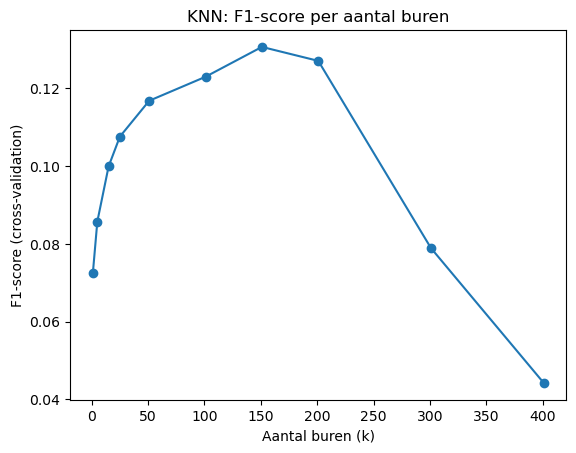

In [10]:
# 5-fold cross-validation; ieder deel bevat 1,54% stroke-patiënten
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_waarden = [1, 5, 15, 25, 51, 101, 151, 201, 301, 401]
f1_per_k = []

for k in k_waarden:
    # Pipeline: standaardiseren -> undersampling -> KNN met k buren
    knn_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("under", RandomUnderSampler(sampling_strategy=0.5,
                                     random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    # Gemiddelde F1-score over de 5 folds
    f1 = cross_val_score(knn_pipe, X_train, y_train, cv=cv,
                         scoring="f1", n_jobs=-1).mean()
    f1_per_k.append(f1)
    print(f"k = {k:3d} | F1 = {f1:.3f}")

# Grafiek: F1-score per k
plt.plot(k_waarden, f1_per_k, marker="o")
plt.xlabel("Aantal buren (k)")
plt.ylabel("F1-score (cross-validation)")
plt.title("KNN: F1-score per aantal buren")
plt.show()

**Observaties:**
- **Bij *k* = 1 is de F1-score laag (0,07): overfitting.** Iedere voorspelling hangt af van één buur. Toevallige uitzonderingen in de trainingsdata bepalen dan de voorspelling.
- **Naarmate *k* groter wordt, stijgt de F1-score** tot een maximum van ongeveer 0,13 rond *k* = 151. Meer buren maken de voorspelling stabieler.
- **Bij een te grote *k* daalt de F1-score weer sterk** (0,04 bij *k* = 401): underfitting. Na undersampling bevat iedere trainingsfold ongeveer 1.000 patiënten; bij 401 buren stemt bijna de helft van de data mee, waardoor vrijwel altijd de grootste klasse (geen stroke) wint.
- De keuze van *k* bepaalt dus de balans tussen overfitting en underfitting. De beste combinatie van *k* en de andere hyperparameters zoeken we in 6.1.5.

#### 6.1.5 Hyperparameter tuning
**Hyperparameters** zijn instellingen van een model die we zelf kiezen vóór het trainen. Met GridSearchCV testen we alle combinaties van de onderstaande waarden met 5-fold cross-validation, en kiezen we de combinatie met de hoogste gemiddelde F1-score:

| Hyperparameter | Betekenis | Geteste waarden |
|---|---|---|
| `n_neighbors` | Aantal buren *k* | 51, 101, 151, 201 |
| `p` | Afstandsmaat: 1 = manhattan, 2 = euclidean | 1, 2 |
| `weights` | `uniform`: iedere buur telt even zwaar; `distance`: dichtbije buren tellen zwaarder | uniform, distance |
| `sampling_strategy` | Verhouding stroke : geen stroke na undersampling | 0,2 (1 : 5), 0,5 (1 : 2), 1,0 (1 : 1) |

Voor *k* testen we alleen 51 tot 201, omdat de beste F1-scores in 6.1.4 in dat gebied lagen. In totaal zijn dit 4 × 2 × 2 × 3 = 48 combinaties, die ieder 5 keer worden getraind (240 keer in totaal).

In [12]:
# Pipeline: standaardiseren -> undersampling -> KNN
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("under", RandomUnderSampler(random_state=42)),
    ("knn", KNeighborsClassifier()),
])

# Alle hyperparameters en waarden die we willen testen
param_grid = {
    "knn__n_neighbors": [51, 101, 151, 201],
    "knn__p": [1, 2],
    "knn__weights": ["uniform", "distance"],
    "under__sampling_strategy": [0.2, 0.5, 1.0],
}

# Test alle combinaties met 5-fold cross-validation op de F1-score
grid_knn = GridSearchCV(knn_pipe, param_grid, scoring="f1", cv=cv,
                        n_jobs=-1)
grid_knn.fit(X_train, y_train)

print("Beste hyperparameters:", grid_knn.best_params_)
print("Beste F1-score (cross-validation):", round(grid_knn.best_score_, 3))

# Top 5 van de beste combinaties
resultaten = pd.DataFrame(grid_knn.cv_results_)
kolommen = ["param_knn__n_neighbors", "param_knn__p", "param_knn__weights",
            "param_under__sampling_strategy", "mean_test_score"]
resultaten.sort_values("mean_test_score", ascending=False)[kolommen].head(5).round(4)

Beste hyperparameters: {'knn__n_neighbors': 101, 'knn__p': 1, 'knn__weights': 'distance', 'under__sampling_strategy': 0.5}
Beste F1-score (cross-validation): 0.134


,param_knn__n_neighbors,param_knn__p,param_knn__weights,param_under__sampling_strategy,mean_test_score
16,101,1,distance,0.5,0.1339
1,51,1,uniform,0.5,0.1336
13,101,1,uniform,0.5,0.1330
46,201,2,distance,0.5,0.1325
34,151,2,distance,0.5,0.1313


**Observaties:**
- De beste combinatie is **k = 101**, **manhattan** (`p = 1`), `weights = "distance"` en een verhouding van **1 : 2** na undersampling, met een F1-score van **0,134**.
- **De verhouding na undersampling maakt het meeste uit.** 1 : 2 scoort het best; 1 : 5 (0,117) en 1 : 1 (0,093) scoren lager. De andere instellingen maken weinig verschil: de top 5 ligt tussen 0,131 en 0,134.
- KNN scoort hiermee beter dan het model dat altijd "stroke" voorspelt (F1 0,03, zie hoofdstuk 5), maar de F1-score blijft laag. Stroke is moeilijk te voorspellen met KNN.

#### 6.1.6 Drempel kiezen
KNN geeft per patiënt een **kans op stroke**: het aandeel buren met stroke. Standaard voorspelt het model "stroke" als die kans **0,5 of hoger** is. Dat is de **drempel** (techniek 2, zie 6.1.3).

Met `cross_val_predict` berekenen we deze kansen alleen op de trainset, zodat de validatieset eerlijk blijft. Daarna berekenen we de F1-score bij drempels van 0,05 tot 0,7, voor het beste model **met** undersampling en hetzelfde model **zonder** undersampling.

In [13]:
# Het beste model uit 6.1.5 (met undersampling)
knn_best = grid_knn.best_estimator_

# Hetzelfde KNN-model, maar zonder undersampling
knn_zonder = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=101, p=1, weights="distance")),
])

# Kans op stroke per patiënt (kolom 1), berekend met cross-validation
kansen_met = cross_val_predict(knn_best, X_train, y_train, cv=cv,
                               method="predict_proba", n_jobs=-1)[:, 1]
kansen_zonder = cross_val_predict(knn_zonder, X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=-1)[:, 1]

# F1-score per drempel: stroke als de kans >= drempel
for drempel in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    f1_met = f1_score(y_train, kansen_met >= drempel)
    f1_zonder = f1_score(y_train, kansen_zonder >= drempel)
    print(f"Drempel {drempel:.2f} | met undersampling: {f1_met:.3f} "
          f"| zonder: {f1_zonder:.3f}")

Drempel 0.05 | met undersampling: 0.037 | zonder: 0.121
Drempel 0.10 | met undersampling: 0.042 | zonder: 0.087
Drempel 0.20 | met undersampling: 0.055 | zonder: 0.009
Drempel 0.30 | met undersampling: 0.076 | zonder: 0.000
Drempel 0.40 | met undersampling: 0.098 | zonder: 0.000
Drempel 0.50 | met undersampling: 0.133 | zonder: 0.000
Drempel 0.60 | met undersampling: 0.118 | zonder: 0.000
Drempel 0.70 | met undersampling: 0.032 | zonder: 0.000


**Observaties:**
- **Zonder undersampling** vindt het model bij drempel 0,5 geen enkele stroke-patiënt (F1 = 0). Met een lage drempel van **0,05** stijgt de F1-score naar **0,121**. Drempel aanpassen werkt dus.
- **Met undersampling** is **0,5** de beste drempel (F1 0,133). Undersampling heeft de kansen al zo verschoven dat de drempel niet meer aangepast hoeft te worden.
- We kiezen het model **met undersampling en drempel 0,5**, omdat dit de hoogste F1-score geeft.

#### 6.1.7 Evaluatie op de validatieset
Nu testen we het gekozen model op de **validatieset**: 6.709 patiënten die het model nog niet heeft gezien.

F1-score:  0.109
Precision: 0.064
Recall:    0.359


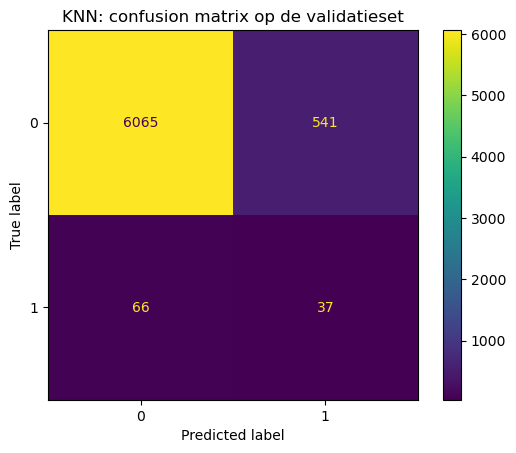

In [14]:
# predict() gebruikt de standaarddrempel 0,5: onze beste drempel
y_val_pred = knn_best.predict(X_val)

print("F1-score: ", round(f1_score(y_val, y_val_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_pred), 3))
print("Recall:   ", round(recall_score(y_val, y_val_pred), 3))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
plt.title("KNN: confusion matrix op de validatieset")
plt.show()

**Observaties:**
- Het model vindt **37 van de 103** stroke-patiënten (recall **0,359**). Het model in hoofdstuk 5 vond er **0**.
- Daar staat veel vals alarm tegenover: van de 578 patiënten die het model als "stroke" aanwijst, hebben er maar 37 echt stroke (precision **0,064**).
- De F1-score is **0,109**: iets lager dan in de cross-validation (0,134), maar boven het Kaggle-minimum van 0,1.
- Er worden nog **66 stroke-patiënten** gemist (False Negatives). In deze medische toepassing is dat de ergste fout (zie hoofdstuk 2).

#### 6.1.8 Kaggle-inzending
We trainen het gekozen model (k = 101, manhattan, `distance`, undersampling 1 : 2, drempel 0,5) opnieuw op **alle** trainingsdata: de trainset én de validatieset. Zo leert het model van 517 in plaats van 414 stroke-patiënten. Daarna voorspellen we de patiënten in `test.csv` en slaan we de voorspellingen op in het formaat van `sample_submission.csv` (kolommen `id` en `stroke`).

In [15]:
# Train het beste model opnieuw op alle data (train + validatie)
knn_best.fit(X, y)

# Voorspel stroke (0 of 1) voor elke patiënt in de testset
test_pred = knn_best.predict(X_test)

# Inleverbestand met de kolommen id en stroke
test_ids = pd.read_csv("../data/test.csv")["id"]
submission = pd.DataFrame({"id": test_ids, "stroke": test_pred})
submission.to_csv("submission_knn.csv", index=False)

print(submission.shape)
print(submission["stroke"].value_counts())
submission.head()

(8388, 2)
stroke
0    7796
1     592
Name: count, dtype: int64


,id,stroke
0,32840,0
1,45158,0
2,56105,0
3,3112,0
4,35224,0


**Observaties:**
- Het inleverbestand heeft **8.388 rijen**: één voorspelling per patiënt in de testset.
- Het model voorspelt bij **592 patiënten (7,1%)** stroke. Dat is vergelijkbaar met de validatieset (578 van 6.709 = 8,6%).
- Kaggle-score (F1): **[score invullen]**.

#### 6.1.9 Conclusie KNN
- **Beste model:** k = 101, manhattan afstand, `weights="distance"`, random undersampling naar 1 : 2 en drempel 0,5.
- **F1-scores:** 0,134 (cross-validation), 0,109 (validatieset) en **[score]** (Kaggle).
- **Imbalance:** zonder technieken vindt KNN geen stroke-patiënten. Undersampling werkt het best; drempel aanpassen helpt alleen zonder undersampling.
- **Beperking:** het model vindt ongeveer 1 op de 3 stroke-patiënten, maar geeft veel vals alarm (precision 0,064). In opdracht 4 vergelijken we KNN met de andere modellen.